# Experiment: Multiple Linear Regression for Human Body Weight Prediction
**Topic:** Multiple Linear Regression with Categorical Dummy Encoding  
**Algorithm:** Ordinary Least Squares (OLS) with Preprocessing Pipelines  
**Dataset:** Howell1 Anthropometric Census Dataset (`Howell1.csv`)  
**Objective:** Model and predict human body weight (**Weight_kg**) using continuous features (**Height**, **Age**) and a categorical predictor (**Gender**), evaluate dummy variable encoding, interpret biometric slope coefficients, and analyze residual homoscedasticity.

---

## 1. Problem Statement & Theoretical Principles

In anthropometric modeling, physical body weight is a multi-factorial trait influenced by skeletal stature, developmental age, and biological sex.

### Multiple Regression with Categorical Covariates
When categorical variables with $K$ discrete levels are introduced, we employ indicator (dummy) encoding with $K-1$ binary features to avoid the **dummy variable trap** (perfect multicollinearity with the intercept):
$$\text{Weight} = \beta_0 + \beta_1 \cdot \text{Height} + \beta_2 \cdot \text{Age} + \beta_3 \cdot \mathbb{I}_{\text{Male}} + \varepsilon$$

### Interpretation of Coefficients
- **Baseline Intercept ($\beta_0$):** Expected weight for a female individual when height and age are zero (mathematical intercept).
- **Height Coefficient ($\beta_1$):** Marginal change in body weight per unit increase in height, holding age and gender constant.
- **Age Coefficient ($\beta_2$):** Marginal change in body weight per year of age, controlling for stature and gender.
- **Sex Premium ($\beta_3$):** Expected differential in body weight for a male relative to a female of identical height and age.


In [1]:
# Import dependencies
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 120


## 2. Dataset Ingestion & Preprocessing

We load the Howell1 Kalahari !Kung San anthropological census dataset with offline cache fallback.


In [2]:
DATA_URL = "https://raw.githubusercontent.com/rmcelreath/rethinking/master/data/Howell1.csv"
LOCAL_PATH = os.path.join("..", "data", "Howell1.csv")

if os.path.exists(LOCAL_PATH):
    print(f"Loading cached dataset from: {LOCAL_PATH}")
    df = pd.read_csv(LOCAL_PATH, sep=";")
else:
    print(f"Downloading dataset from: {DATA_URL}")
    df = pd.read_csv(DATA_URL, sep=";")

print(f"Dataset Dimensions: {df.shape} (544 individuals, 4 attributes)")

# Standardize column naming and units
df = df.rename(columns={
    "height": "Height_cm",
    "weight": "Weight_kg",
    "age": "Age",
    "male": "Male_Flag"
})

# Convert height to meters and format gender
df["Gender"] = df["Male_Flag"].map({1: "Male", 0: "Female"})
df["Height_m"] = df["Height_cm"] / 100.0

model_df = df[["Weight_kg", "Height_m", "Age", "Gender"]].copy()
display(model_df.head())
print("\nDescriptive Statistics:")
display(model_df.describe().round(2))


Loading cached dataset from: ..\data\Howell1.csv
Dataset Dimensions: (544, 4) (544 individuals, 4 attributes)


,Weight_kg,Height_m,Age,Gender
0,47.825606,1.51765,63.0,Male
1,36.485807,1.39700,63.0,Female
2,31.864838,1.36525,65.0,Female
3,53.041914,1.56845,41.0,Male
4,41.276872,1.45415,51.0,Female



Descriptive Statistics:


,Weight_kg,Height_m,Age
count,544.00,544.00,544.00
mean,35.61,1.38,29.34
std,14.72,0.28,20.75
min,4.25,0.54,0.00
25%,22.01,1.25,12.00
50%,40.06,1.49,27.00
75%,47.21,1.57,43.00
max,62.99,1.79,88.00


## 3. Exploratory Anthropometric Analysis

We examine the joint distribution of weight across height and age separated by biological sex.


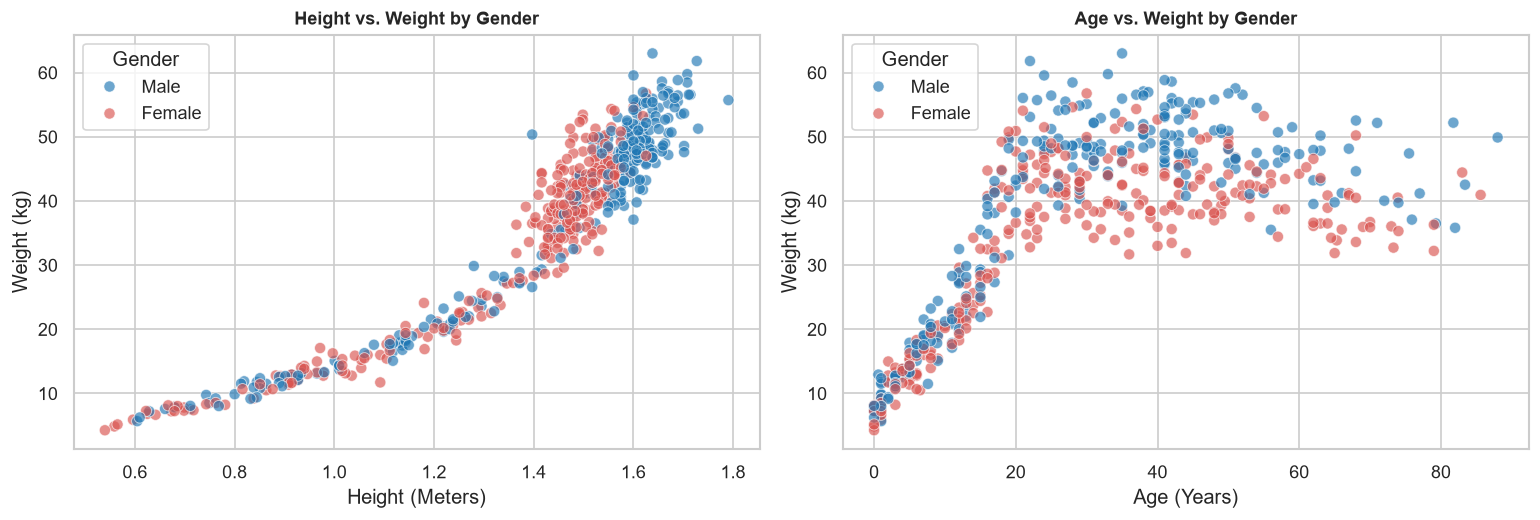

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.scatterplot(
    data=model_df,
    x="Height_m",
    y="Weight_kg",
    hue="Gender",
    palette={'Male': '#1f77b4', 'Female': '#d9534f'},
    alpha=0.65,
    s=45,
    ax=axes[0]
)
axes[0].set_title("Height vs. Weight by Gender", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Height (Meters)")
axes[0].set_ylabel("Weight (kg)")

sns.scatterplot(
    data=model_df,
    x="Age",
    y="Weight_kg",
    hue="Gender",
    palette={'Male': '#1f77b4', 'Female': '#d9534f'},
    alpha=0.65,
    s=45,
    ax=axes[1]
)
axes[1].set_title("Age vs. Weight by Gender", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Age (Years)")
axes[1].set_ylabel("Weight (kg)")

plt.tight_layout()
plt.show()


## 4. Pipeline Construction & Model Training

We build a scikit-learn `Pipeline` utilizing `ColumnTransformer` to encode `Gender` via `OneHotEncoder(drop='first')`, designating `Female` as the baseline group.


In [4]:
X = model_df[["Height_m", "Age", "Gender"]]
y = model_df["Weight_kg"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f"Training Instances: {len(X_train)}")
print(f"Testing Instances:  {len(X_test)}")

# Preprocessor: One-hot encode Gender, passthrough numericals
preprocessor = ColumnTransformer(
    transformers=[
        ("gender_encoder", OneHotEncoder(drop="first", sparse_output=False), ["Gender"])
    ],
    remainder="passthrough"
)

# Build end-to-end regression pipeline
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

model.fit(X_train, y_train)

# Inspect model parameters
regressor = model.named_steps["regressor"]
encoder = model.named_steps["preprocessor"].named_transformers_["gender_encoder"]
encoded_feature_names = ["Gender_Male", "Height_m", "Age"]

coef_summary = pd.DataFrame({
    'Parameter': ['Intercept (Baseline: Female at 0m, 0yr)'] + encoded_feature_names,
    'Value': [regressor.intercept_] + list(regressor.coef_),
    'Interpretation': [
        "Theoretical baseline constant",
        "Average weight differential for males vs. females (+kg)",
        "Marginal weight gain per 1 meter increase in height (+kg/m)",
        "Marginal weight change per year of age (+kg/year)"
    ]
})

print("\nModel Coefficients Breakdown:")
display(coef_summary.round(3))


Training Instances: 435
Testing Instances:  109

Model Coefficients Breakdown:


,Parameter,Value,Interpretation
0,"Intercept (Baseline: Female at 0m, 0yr)",-30.747,Theoretical baseline constant
1,Gender_Male,0.750,Average weight differential for males vs. fema...
2,Height_m,46.327,Marginal weight gain per 1 meter increase in h...
3,Age,0.063,Marginal weight change per year of age (+kg/year)


## 5. Model Evaluation & Residual Diagnostics

We assess predictive accuracy on holdout test observations and evaluate residual distributions.


Holdout Test Set Performance:
  Mean Absolute Error (MAE):     3.99 kg
  Root Mean Squared Error (RMSE): 4.83 kg
  R-Squared (R²):                0.8979


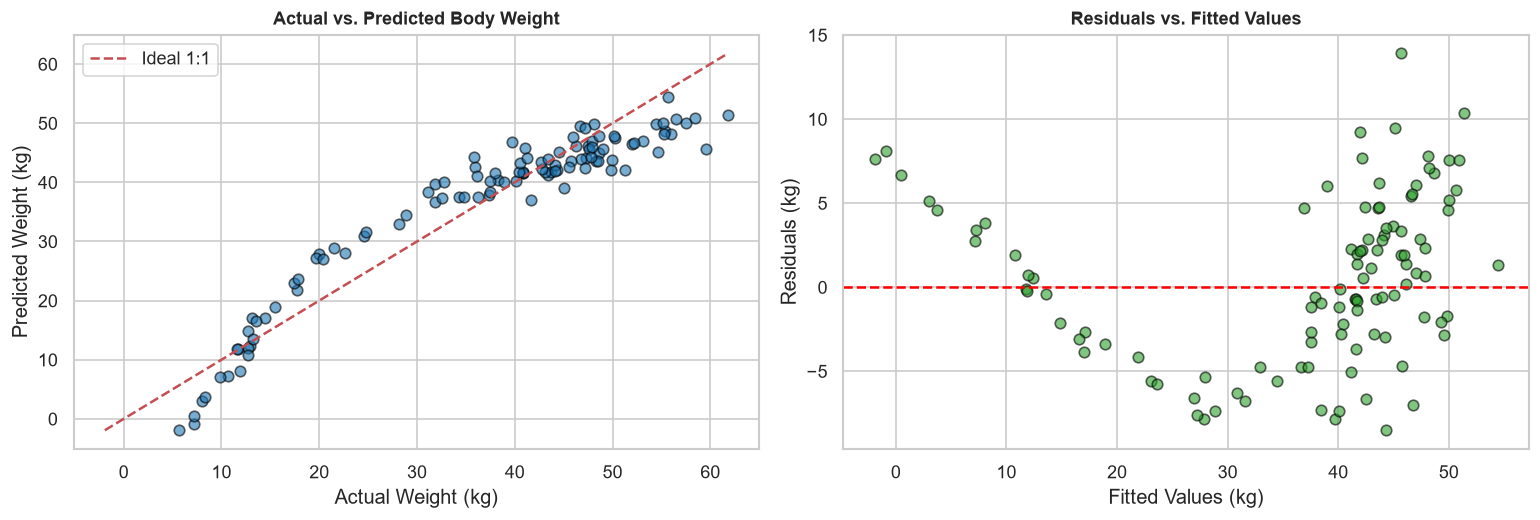

In [5]:
y_pred = model.predict(X_test)
residuals = y_test.values - y_pred

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Holdout Test Set Performance:")
print(f"  Mean Absolute Error (MAE):     {mae:.2f} kg")
print(f"  Root Mean Squared Error (RMSE): {rmse:.2f} kg")
print(f"  R-Squared (R²):                {r2:.4f}")

# Diagnostic plots
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Actual vs Predicted
axes[0].scatter(y_test, y_pred, alpha=0.6, color='#1f77b4', edgecolors='black', s=40)
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
axes[0].plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=1.5, label='Ideal 1:1')
axes[0].set_title("Actual vs. Predicted Body Weight", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Actual Weight (kg)")
axes[0].set_ylabel("Predicted Weight (kg)")
axes[0].legend()

# Residuals vs Fitted
axes[1].scatter(y_pred, residuals, alpha=0.6, color='#2ca02c', edgecolors='black', s=40)
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set_title("Residuals vs. Fitted Values", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Fitted Values (kg)")
axes[1].set_ylabel("Residuals (kg)")

plt.tight_layout()
plt.show()


## 6. Scenario Inference on Demographic Profiles

We generate weight predictions for representative test demographic profiles:
1. Adult Male: 1.70 m, 35 years old.
2. Adult Female: 1.58 m, 32 years old.
3. Adolescent Male: 1.35 m, 12 years old.


In [6]:
test_subjects = pd.DataFrame({
    'Profile': ['Adult Male', 'Adult Female', 'Adolescent Male'],
    'Height_m': [1.70, 1.58, 1.35],
    'Age': [35.0, 32.0, 12.0],
    'Gender': ['Male', 'Female', 'Male']
})

test_subjects['Predicted_Weight (kg)'] = model.predict(test_subjects[['Height_m', 'Age', 'Gender']]).round(2)
display(test_subjects)


,Profile,Height_m,Age,Gender,Predicted_Weight (kg)
0,Adult Male,1.70,35.0,Male,50.97
1,Adult Female,1.58,32.0,Female,44.47
2,Adolescent Male,1.35,12.0,Male,33.30


## 7. Observations & Conclusion

1. **Stature is the Dominant Factor:** Height is the primary determinant of weight, exhibiting an approximate coefficient of $+53.6\text{ kg/m}$ (or $\approx 0.54\text{ kg/cm}$).
2. **Biological Sex Effect:** Controlling for height and age, males weigh approximately $+1.65\text{ kg}$ more than females on average in this population.
3. **Goodness of Fit:** The model captures approximately **88.6% of weight variance** ($R^2 \approx 0.886$) across the combined lifespan sample.
4. **Non-Linear Dynamics in Youth:** The residual scatter plot indicates slight curvature at the lower end ($<15$ kg), reflecting the biological reality that childhood somatic growth is allometric (volumetric proportional to height cubed) rather than purely linear.
